In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/sample_submission.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/metadata.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv


# Heavy Equipment Selling Price Prediction

## 1. Project Introduction

This project predicts the selling price of heavy equipment using information about the equipment and its transaction.

This is a regression problem because `TargetValue` is a continuous numerical value.

The evaluation metric is Root Mean Squared Logarithmic Error (RMSLE). A lower RMSLE indicates better predictions. RMSLE focuses on relative prediction errors and reduces the influence of extremely large prices.

### Objective

The objective is to understand the dataset, preprocess it without data leakage, compare multiple regression models, analyze their performance, and generate predictions for the competition test data.

## 2. Import Libraries

This section imports the libraries required for data manipulation, visualization, preprocessing, model training, and evaluation.

A fixed random seed is used to make the results reproducible.

In [2]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_log_error
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from catboost import CatBoostRegressor

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")

## 3. Load Dataset
The training data contains equipment records with known selling prices. The test data contains records whose selling prices must be predicted.

The sample submission defines the exact columns and row order required for the final submission.

In [3]:
INPUT_ROOT = "/kaggle/input"
print("Available input folders:", os.listdir(INPUT_ROOT))

required_files = {
    "train.csv",
    "test.csv",
    "sample_submission.csv"
}

DATA_DIR = None

# Search all folders under /kaggle/input
for current_folder, subfolders, files in os.walk(INPUT_ROOT):
    if required_files.issubset(set(files)):
        DATA_DIR = current_folder
        break

if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not find train.csv, test.csv and sample_submission.csv."
    )

print("Using data folder:", DATA_DIR)

train = pd.read_csv(
    os.path.join(DATA_DIR, "train.csv"),
    low_memory=False
)

test = pd.read_csv(
    os.path.join(DATA_DIR, "test.csv"),
    low_memory=False
)

sample_submission = pd.read_csv(
    os.path.join(DATA_DIR, "sample_submission.csv"),
    low_memory=False
)

print("Training shape:", train.shape)
print("Test shape:", test.shape)
display(train.head())

TARGET = "TargetValue"
ID_COLUMN = "TransactionID"

print("\nTarget is in training data:", TARGET in train.columns)
print("Target is in test data:", TARGET in test.columns)

Available input folders: ['competitions']
Using data folder: /kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge
Training shape: (138701, 50)
Test shape: (15000, 49)


,TransactionID,TargetValue,AssetID,ProductConfigID,DataOriginCode,VendorPartnerID,ManufactureYear,OperationalHoursMeter,UtilizationTier,TransactionDate,Spec_FullDescriptor,Spec_BaseClass,Spec_SubClass,Spec_ReleaseSeries,Spec_VariantModifier,AssetScaleFactor,FunctionalClassification,RegionCode,InventoryGroupCategory,InventoryGroupDescription,col1,CabinType,Forks,col3,col4,DrivetrainType,col5,col6,col7,col8,col9,col10,col11,col12,col13,col14,col15,col16,col18,col19,col20,col21,col22,col23,col24,col25,col27,col28,col29,col30
0,1139309,57000.0,117665,88,ACH138,GTX,1997,4640.0,Low,2005-03-26,950FII,950,F,II,NaN,Medium,Wheel Loader - 150.0 to 175.0 Horsepower,North Carolina,WL,Wheel Loader,NaN,EROPS w AC,None or Unspecified,None or Unspecified,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2 Valve,NaN,NaN,NaN,NaN,23.5,None or Unspecified,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Standard,Conventional
1,1139316,26500.0,1001282,4616,ACH138,GTX,2005,508.0,Low,2009-12-18,310G,310,G,NaN,NaN,NaN,Backhoe Loader - 14.0 to 15.0 Ft Standard Digg...,Arizona,BL,Backhoe Loaders,Four Wheel Drive,OROPS,None or Unspecified,No,Extended,Powershuttle,None or Unspecified,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1139317,21000.0,772709,1948,ACH138,GTX,1994,11540.0,High,2005-08-26,790ELC,790,E,NaN,LC,Large / Medium,"Hydraulic Excavator, Track - 21.0 to 24.0 Metr...",Florida,TEX,Track Excavators,NaN,EROPS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Standard,NaN,NaN,NaN,NaN,NaN,None or Unspecified,NaN,NaN,Steel,None or Unspecified,None or Unspecified,None or Unspecified,None or Unspecified,Double,NaN,NaN,NaN,NaN
3,1139322,27000.0,902010,3550,ACH138,GTX,2002,4883.0,High,2006-11-17,416D,416,D,NaN,NaN,NaN,Backhoe Loader - 14.0 to 15.0 Ft Standard Digg...,Illinois,BL,Backhoe Loaders,Four Wheel Drive,OROPS,None or Unspecified,No,Standard,Standard,Yes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1139333,21500.0,1036259,36014,ACH138,GTX,2009,302.0,Low,2010-08-27,430HAG,430,HAG,NaN,NaN,Mini,"Hydraulic Excavator, Track - 3.0 to 4.0 Metric...",Texas,TEX,Track Excavators,NaN,EROPS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Auxiliary,NaN,NaN,NaN,NaN,NaN,Manual,NaN,NaN,Rubber,None or Unspecified,None or Unspecified,None or Unspecified,None or Unspecified,Double,NaN,NaN,NaN,NaN



Target is in training data: True
Target is in test data: False


### Observation

The training dataset contains the target column `TargetValue`, while the test dataset does not.

### Decision

`TargetValue` will be separated before training. `TransactionID` will be preserved for the final submission but will not be used as a model feature.

## 4. Understand the Dataset

Examining data types, descriptive statistics, and unique values helps us understand the available information.

Numerical features contain measurable values. Categorical features represent groups or labels and generally require encoding for many machine-learning algorithms.

In [4]:
train.info()

print("\nData types:")
display(train.dtypes.to_frame("Data Type"))

raw_numerical_columns = train.drop(columns=[TARGET]).select_dtypes(
    include=np.number
).columns.tolist()
raw_categorical_columns = train.drop(columns=[TARGET]).select_dtypes(
    exclude=np.number
).columns.tolist()

print("Number of numerical input columns:", len(raw_numerical_columns))
print("Number of categorical input columns:", len(raw_categorical_columns))

print("\nNumerical descriptive statistics:")
display(train.describe(include=[np.number]).T)

print("\nCategorical descriptive statistics:")
display(train.describe(include=["object", "category"]).T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138701 entries, 0 to 138700
Data columns (total 50 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   TransactionID              138701 non-null  int64  
 1   TargetValue                138701 non-null  float64
 2   AssetID                    138701 non-null  int64  
 3   ProductConfigID            138701 non-null  int64  
 4   DataOriginCode             138701 non-null  object 
 5   VendorPartnerID            138701 non-null  object 
 6   ManufactureYear            138701 non-null  int64  
 7   OperationalHoursMeter      82058 non-null   float64
 8   UtilizationTier            50475 non-null   object 
 9   TransactionDate            138701 non-null  object 
 10  Spec_FullDescriptor        138701 non-null  object 
 11  Spec_BaseClass             138701 non-null  object 
 12  Spec_SubClass              101716 non-null  object 
 13  Spec_ReleaseSeries         32

,Data Type
TransactionID,int64
TargetValue,float64
AssetID,int64
ProductConfigID,int64
DataOriginCode,object
VendorPartnerID,object
ManufactureYear,int64
OperationalHoursMeter,float64
UtilizationTier,object
TransactionDate,object


Number of numerical input columns: 5
Number of categorical input columns: 44

Numerical descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
TransactionID,138701.0,2.186276e+06,1.128497e+06,1139309.0,1465754.0,1751884.0,2372139.0,6333410.0
TargetValue,138701.0,4.152187e+04,2.636113e+04,7500.0,20500.0,35000.0,57000.0,142000.0
AssetID,138701.0,1.204814e+06,5.287376e+05,8.0,1007930.0,1246956.0,1495817.0,2478476.0
ProductConfigID,138701.0,7.286422e+03,7.542422e+03,39.0,1693.0,3852.0,11873.0,37209.0
ManufactureYear,138701.0,1.891641e+03,3.069920e+02,1001.0,1990.0,1998.0,2004.0,2015.0
OperationalHoursMeter,82058.0,4.553719e+03,2.792204e+04,0.0,0.0,1620.0,5001.0,1729600.0



Categorical descriptive statistics:


,count,unique,top,freq
DataOriginCode,138701,6,ADI149,59541
VendorPartnerID,138701,31,UJF,67828
UtilizationTier,50475,3,Medium,24588
TransactionDate,138701,3676,2010-02-16,1159
Spec_FullDescriptor,138701,3505,140G,3751
Spec_BaseClass,138701,1249,12,5702
Spec_SubClass,101716,147,G,17381
Spec_ReleaseSeries,32896,113,II,8425
Spec_VariantModifier,52332,132,L,14496
AssetScaleFactor,97491,6,Large / Medium,39222


### Observation

The displayed tables show the ranges, data types, and unique-value counts of the available columns.

They also help identify columns with unusual ranges, missing values, or many categorical levels.

### Decision

Numerical and categorical columns will receive different preprocessing steps.

## 5. Missing Value Analysis

Missing-value analysis shows which columns contain incomplete information and how much data is missing.

Most machine-learning algorithms cannot process missing entries directly, so an appropriate treatment is required.

In [5]:
missing_table = pd.DataFrame({
    "Column": train.columns,
    "Missing Count": train.isna().sum().values,
    "Missing Percentage": (train.isna().mean().values * 100).round(2)
})

missing_table = missing_table[missing_table["Missing Count"] > 0]
missing_table = missing_table.sort_values(
    "Missing Percentage",
    ascending=False
).reset_index(drop=True)

display(missing_table)
print("Columns containing missing values:", len(missing_table))

,Column,Missing Count,Missing Percentage
0,col18,138635,99.95
1,col19,138635,99.95
2,col4,128320,92.52
3,col5,128320,92.52
4,col28,123742,89.21
5,col27,123742,89.21
6,col30,119829,86.39
7,col29,119829,86.39
8,col14,115296,83.13
9,col11,115296,83.13


Columns containing missing values: 35


### Observation

The missing-value table is sorted in descending order so that the columns with the highest missing percentages appear first.

Rows are not removed automatically because they may still contain useful information.

### Decision

- Numerical missing values will be replaced with the median.
- Categorical missing values will be replaced with the most frequent category in the scikit-learn pipeline.
- CatBoost categorical missing values will be represented by `"Unknown"`.

Median imputation is used because it is less sensitive to extreme numerical values.

## 6. Duplicate Check

Duplicate records can give repeated observations more influence during training.

The number of exact duplicates is checked, but duplicates are not removed automatically because repeated transactions may be legitimate.

In [6]:
duplicate_count = train.duplicated().sum()
print("Number of exact duplicate rows:", duplicate_count)

if duplicate_count == 0:
    print("OBSERVATION: No exact duplicate rows were found.")
else:
    print(
        "OBSERVATION: Exact duplicates exist. They are retained because "
        "we do not know whether they are legitimate repeated records."
    )

Number of exact duplicate rows: 0
OBSERVATION: No exact duplicate rows were found.


## 7. Exploratory Data Analysis

Exploratory Data Analysis helps us understand feature distributions and relationships before preprocessing and model training.

The analysis includes the target distribution, manufacture year, operational hours, important categorical features, and their relationships with selling price.

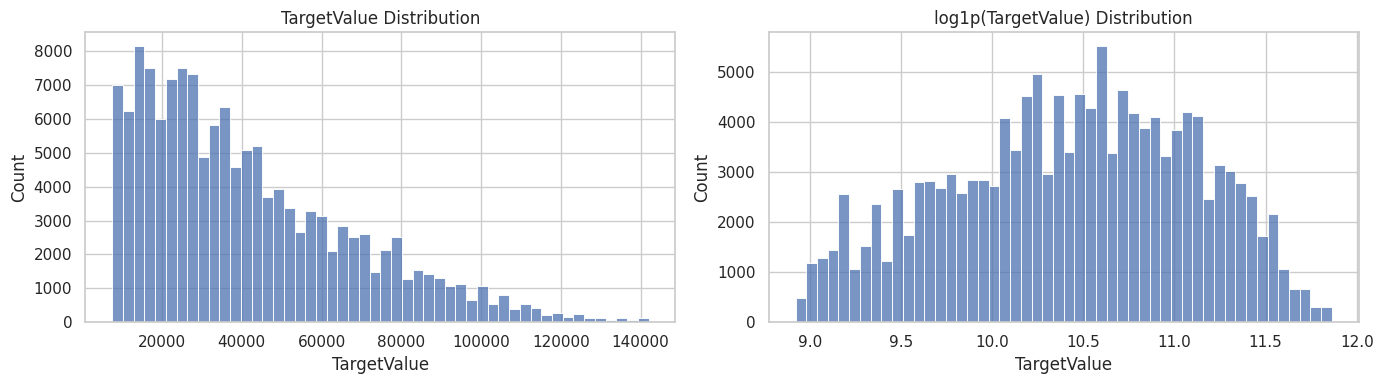

Target skewness: 0.97
Log-target skewness: -0.198
OBSERVATION: The target is not strongly right-skewed.


In [7]:
# Plot 1 and 2: target distribution before and after log1p
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(train[TARGET], bins=50, ax=axes[0])
axes[0].set_title("TargetValue Distribution")
sns.histplot(np.log1p(train[TARGET]), bins=50, ax=axes[1])
axes[1].set_title("log1p(TargetValue) Distribution")
plt.tight_layout()
plt.show()

target_skew = train[TARGET].skew()
log_target_skew = np.log1p(train[TARGET]).skew()
print("Target skewness:", round(target_skew, 3))
print("Log-target skewness:", round(log_target_skew, 3))
print(
    "OBSERVATION: The target is right-skewed."
    if target_skew > 1
    else "OBSERVATION: The target is not strongly right-skewed."
)

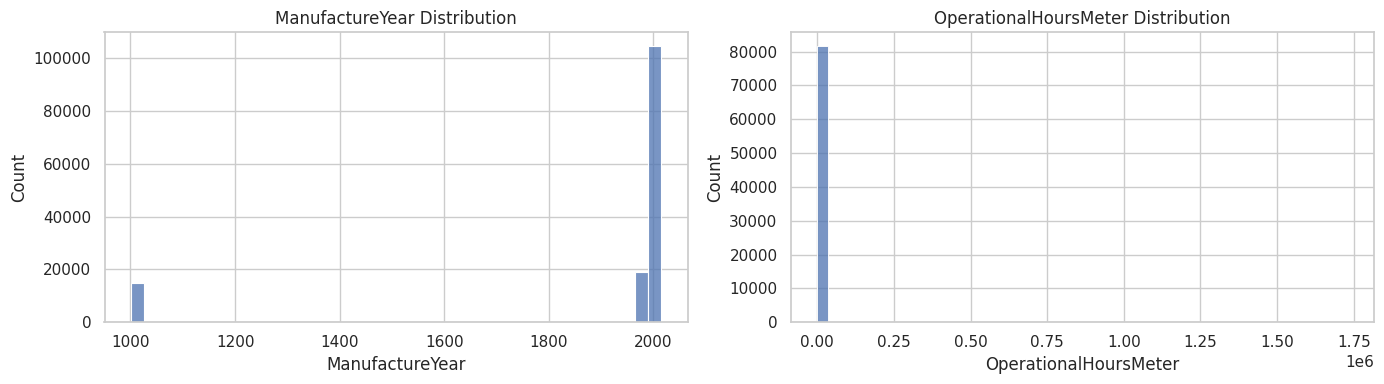

ManufactureYear median: 1998.0
OperationalHoursMeter median: 1620.0
OperationalHoursMeter skewness: 33.282


In [8]:
# Plot 3 and 4: important numerical distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(train["ManufactureYear"].dropna(), bins=40, ax=axes[0])
axes[0].set_title("ManufactureYear Distribution")
sns.histplot(train["OperationalHoursMeter"].dropna(), bins=50, ax=axes[1])
axes[1].set_title("OperationalHoursMeter Distribution")
plt.tight_layout()
plt.show()

print(
    "ManufactureYear median:",
    train["ManufactureYear"].median()
)
print(
    "OperationalHoursMeter median:",
    train["OperationalHoursMeter"].median()
)
print(
    "OperationalHoursMeter skewness:",
    round(train["OperationalHoursMeter"].skew(), 3)
)

In [9]:
# Choose two readable categorical features using the dataset itself
eda_categorical_columns = []
preferred_categories = [
    "ProductGroup",
    "Enclosure",
    "UsageBand",
    "ProductSize",
    "State"
]

for column in preferred_categories:
    if column in train.columns and train[column].nunique(dropna=True) <= 30:
        eda_categorical_columns.append(column)

if len(eda_categorical_columns) < 2:
    for column in raw_categorical_columns:
        unique_count = train[column].nunique(dropna=True)
        if 2 <= unique_count <= 15 and column not in eda_categorical_columns:
            eda_categorical_columns.append(column)
        if len(eda_categorical_columns) == 2:
            break

eda_categorical_columns = eda_categorical_columns[:2]
print("Categorical features selected for EDA:", eda_categorical_columns)

Categorical features selected for EDA: ['DataOriginCode', 'UtilizationTier']


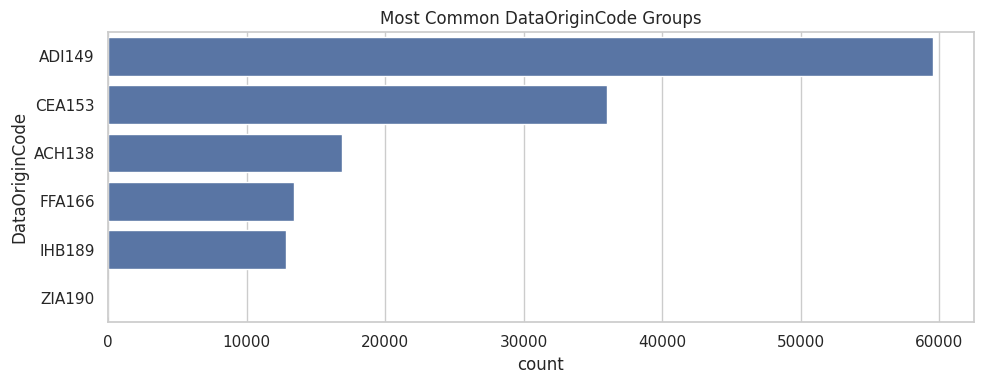

OBSERVATION: The most frequent groups are:


,Count
DataOriginCode,
ADI149,59541
CEA153,36009
ACH138,16909
FFA166,13423
IHB189,12818


In [10]:
# Plot 5: frequency of an important categorical feature
category_1 = eda_categorical_columns[0]
category_order = train[category_1].value_counts().head(12).index

plt.figure(figsize=(10, 4))
sns.countplot(data=train, y=category_1, order=category_order)
plt.title(f"Most Common {category_1} Groups")
plt.tight_layout()
plt.show()

print("OBSERVATION: The most frequent groups are:")
display(train[category_1].value_counts(dropna=False).head(5).to_frame("Count"))

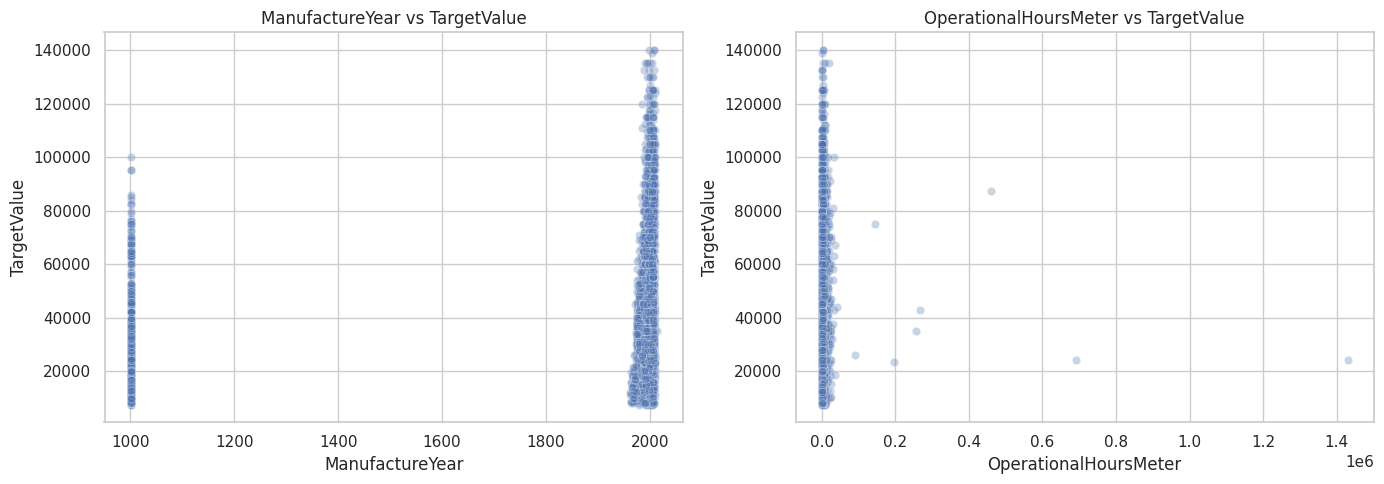

ManufactureYear correlation with TargetValue: 0.204
OperationalHoursMeter correlation with TargetValue: 0.002


In [11]:
# Plot 6 and 7: numerical features versus target
plot_sample = train.sample(
    n=min(5000, len(train)),
    random_state=RANDOM_STATE
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(
    data=plot_sample,
    x="ManufactureYear",
    y=TARGET,
    alpha=0.3,
    ax=axes[0]
)
axes[0].set_title("ManufactureYear vs TargetValue")

sns.scatterplot(
    data=plot_sample,
    x="OperationalHoursMeter",
    y=TARGET,
    alpha=0.3,
    ax=axes[1]
)
axes[1].set_title("OperationalHoursMeter vs TargetValue")
plt.tight_layout()
plt.show()

for column in ["ManufactureYear", "OperationalHoursMeter"]:
    correlation = train[[column, TARGET]].corr().iloc[0, 1]
    print(f"{column} correlation with TargetValue: {correlation:.3f}")

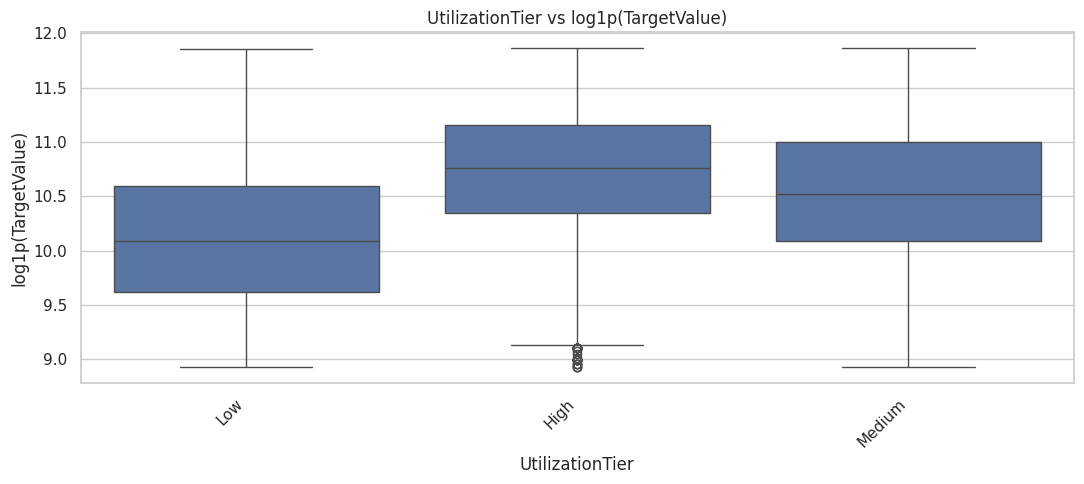

OBSERVATION: Median prices for the displayed groups:


,Median TargetValue
UtilizationTier,
High,47000.0
Medium,37000.0
Low,24000.0


In [12]:
# Plot 8: categorical groups versus target
category_2 = eda_categorical_columns[-1]
top_groups = train[category_2].value_counts().head(10).index
category_plot_data = train[train[category_2].isin(top_groups)].copy()
category_plot_data["LogTarget"] = np.log1p(category_plot_data[TARGET])

plt.figure(figsize=(11, 5))
sns.boxplot(
    data=category_plot_data,
    x=category_2,
    y="LogTarget"
)
plt.xticks(rotation=45, ha="right")
plt.ylabel("log1p(TargetValue)")
plt.title(f"{category_2} vs log1p(TargetValue)")
plt.tight_layout()
plt.show()

category_medians = (
    category_plot_data.groupby(category_2)[TARGET]
    .median()
    .sort_values(ascending=False)
)
print("OBSERVATION: Median prices for the displayed groups:")
display(category_medians.to_frame("Median TargetValue"))

### Decision

The analysis supports the use of a small group of understandable engineered features:

- Transaction date components
- Equipment age
- Manufacture decade
- Log-transformed operational hours
- Specification complexity

The target is also log-transformed to align model training with RMSLE.

## 8. Target Transformation

Equipment prices can have a right-skewed distribution, where a small number of machines have very high prices.

`np.log1p(value)` calculates `log(1 + value)`. It reduces skewness and safely handles zero values.

Training on `log1p(TargetValue)` also aligns the model with RMSLE.

After prediction, `np.expm1(prediction)` converts predictions back to the original price scale.

In [13]:
y_log = np.log1p(train[TARGET])

print("First five original target values:")
display(train[TARGET].head())
print("First five log-transformed target values:")
display(y_log.head())
print("Maximum round-trip difference:",
      np.abs(np.expm1(y_log) - train[TARGET]).max())

First five original target values:


0    57000.0
1    26500.0
2    21000.0
3    27000.0
4    21500.0
Name: TargetValue, dtype: float64

First five log-transformed target values:


0    10.950824
1    10.184938
2     9.952325
3    10.203629
4     9.975855
Name: TargetValue, dtype: float64

Maximum round-trip difference: 1.1641532182693481e-10


## 9. Feature Engineering

Raw transaction dates are difficult for models to use directly. Creating simple derived features makes the information easier for the models to learn.

One reusable function is applied to both training and test data to ensure consistent feature creation.

In [14]:
def create_features(df):
    # Work on a copy so the original DataFrame is unchanged
    df = df.copy()

    transaction_date = pd.to_datetime(
        df["TransactionDate"],
        errors="coerce"
    )

    df["TransactionYear"] = transaction_date.dt.year
    df["TransactionMonth"] = transaction_date.dt.month
    df["TransactionQuarter"] = transaction_date.dt.quarter
    df["TransactionDayOfWeek"] = transaction_date.dt.dayofweek

    df["ManufactureDecade"] = (
        df["ManufactureYear"] // 10
    ) * 10

    df["EquipmentAge"] = (
        df["TransactionYear"] - df["ManufactureYear"]
    )
    invalid_age = (
        (df["EquipmentAge"] < 0) |
        (df["EquipmentAge"] > 100)
    )
    df.loc[invalid_age, "EquipmentAge"] = np.nan

    df["LogOperationalHours"] = np.log1p(
        df["OperationalHoursMeter"].clip(lower=0)
    )

    if "Spec_FullDescriptor" in df.columns:
        descriptor = df["Spec_FullDescriptor"].fillna("").astype(str)
        df["SpecificationComplexity"] = descriptor.str.split().str.len()

    # Date information is now represented by simple numeric columns
    df = df.drop(columns=["TransactionDate"], errors="ignore")
    return df


train_features = create_features(train)
test_features = create_features(test)

engineered_columns = [
    column for column in train_features.columns
    if column not in train.columns
]
print("Engineered features:", engineered_columns)
print("Training feature shape:", train_features.shape)
print("Test feature shape:", test_features.shape)

Engineered features: ['TransactionYear', 'TransactionMonth', 'TransactionQuarter', 'TransactionDayOfWeek', 'ManufactureDecade', 'EquipmentAge', 'LogOperationalHours', 'SpecificationComplexity']
Training feature shape: (138701, 57)
Test feature shape: (15000, 56)


### Observation

The engineered features have the following meanings:

- `TransactionYear` represents the year of the transaction.
- `TransactionMonth` represents the transaction month.
- `TransactionQuarter` groups the transaction into one of four quarters.
- `TransactionDayOfWeek` represents the day of the week.
- `ManufactureDecade` groups machines by production period.
- `EquipmentAge` estimates the machine's age when the transaction occurred.
- `LogOperationalHours` reduces the effect of extreme meter readings.
- `SpecificationComplexity` counts words in the full specification when that column is available.

### Decision

The same feature-engineering function will be applied before training and final prediction.

## 10. Train-Validation Split

The training portion is used to teach the model. The validation portion is used to evaluate performance on unseen examples.

The competition test data is not used for model selection.

## Data Leakage Prevention

Data leakage occurs when validation or test information influences model training.

The data is split before learned preprocessing. Imputation, scaling, and encoding are fitted only on the training portion through a pipeline.

In [15]:
# Separate input features and target
X = train_features.drop(columns=[TARGET, ID_COLUMN], errors="ignore")
y = train_features[TARGET].copy()
y_log = np.log1p(y)

# Keep test IDs for submission, but do not use IDs as a model feature
test_ids = test_features[ID_COLUMN].copy()
X_test = test_features.drop(columns=[ID_COLUMN], errors="ignore")

# Split data so we can evaluate on unseen examples
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

y_train_log = np.log1p(y_train)

print("X_train shape:", X_train.shape)
print("X_valid shape:", X_valid.shape)
print("X_test shape:", X_test.shape)

X_train shape: (110960, 55)
X_valid shape: (27741, 55)
X_test shape: (15000, 55)


## 11. Preprocessing

Ridge Regression and Random Forest require numerical input.

Numerical columns use median imputation and standard scaling. Categorical columns use most-frequent imputation and one-hot encoding.

Standard scaling uses:

`x_scaled = (x - training mean) / training standard deviation`

Scaling is important for Ridge Regression because its coefficients are affected by feature scale. Tree-based models generally do not require scaling.

In [16]:
numerical_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()
categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:")
print(numerical_features)
print("\nCategorical features:")
print(categorical_features)

numerical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numerical", numerical_preprocessor, numerical_features),
    ("categorical", categorical_preprocessor, categorical_features)
])

Numerical features:
['AssetID', 'ProductConfigID', 'ManufactureYear', 'OperationalHoursMeter', 'TransactionYear', 'TransactionMonth', 'TransactionQuarter', 'TransactionDayOfWeek', 'ManufactureDecade', 'EquipmentAge', 'LogOperationalHours', 'SpecificationComplexity']

Categorical features:
['DataOriginCode', 'VendorPartnerID', 'UtilizationTier', 'Spec_FullDescriptor', 'Spec_BaseClass', 'Spec_SubClass', 'Spec_ReleaseSeries', 'Spec_VariantModifier', 'AssetScaleFactor', 'FunctionalClassification', 'RegionCode', 'InventoryGroupCategory', 'InventoryGroupDescription', 'col1', 'CabinType', 'Forks', 'col3', 'col4', 'DrivetrainType', 'col5', 'col6', 'col7', 'col8', 'col9', 'col10', 'col11', 'col12', 'col13', 'col14', 'col15', 'col16', 'col18', 'col19', 'col20', 'col21', 'col22', 'col23', 'col24', 'col25', 'col27', 'col28', 'col29', 'col30']


### Decision

`ColumnTransformer` applies different preprocessing steps to numerical and categorical columns.

`Pipeline` combines preprocessing and modeling. When `.fit()` is called, all learned preprocessing values come only from the training data. When `.predict()` is called, the same transformations are applied automatically.

## 12. Evaluation Metric

Root Mean Squared Logarithmic Error measures the difference between the logarithms of actual and predicted prices.

RMSLE emphasizes relative errors and reduces the influence of extremely large prices.

Predictions are clipped at zero because equipment selling prices cannot be negative. Lower RMSLE is better.

In [17]:
def rmsle(y_true, y_pred):
    y_pred = np.maximum(y_pred, 0)
    return np.sqrt(mean_squared_log_error(y_true, y_pred))


def evaluate_model(model_name, model, uses_log_predictions=True):
    train_output = model.predict(X_train)
    valid_output = model.predict(X_valid)

    if uses_log_predictions:
        train_predictions = np.expm1(train_output)
        valid_predictions = np.expm1(valid_output)
    else:
        train_predictions = train_output
        valid_predictions = valid_output

    train_score = rmsle(y_train, train_predictions)
    valid_score = rmsle(y_valid, valid_predictions)

    print(f"{model_name} Train RMSLE: {train_score:.5f}")
    print(f"{model_name} Validation RMSLE: {valid_score:.5f}")
    return train_score, valid_score, valid_predictions

## 13. Model 1 - Ridge Regression

Ridge Regression is used as a simple linear baseline.

It learns a weighted combination of the encoded features. Regularization prevents the coefficients from becoming excessively large.

A linear model is useful for determining whether simple relationships are sufficient for the prediction problem.

In [18]:
ridge_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=1.0, solver="lsqr"))
])

ridge_pipeline.fit(X_train, y_train_log)
ridge_train_rmsle, ridge_valid_rmsle, ridge_valid_predictions = evaluate_model(
    "Ridge Regression",
    ridge_pipeline
)

Ridge Regression Train RMSLE: 0.26709
Ridge Regression Validation RMSLE: 0.27600


### Observation

The training and validation RMSLE values help diagnose model behavior.

If both scores are relatively poor, the model may be underfitting. If training RMSLE is much lower than validation RMSLE, the model may be overfitting.

The model-comparison table calculates the actual difference between these scores.

## 14. Model 2 - Random Forest

Random Forest combines predictions from multiple decision trees.

It can capture nonlinear relationships and interactions that a linear model may miss. Averaging multiple trees generally makes predictions more stable than using one decision tree.

A moderate number of trees and limited depth are used to control runtime and overfitting.

In [19]:
random_forest_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=50,
        max_depth=12,
        min_samples_split=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

random_forest_pipeline.fit(X_train, y_train_log)
rf_train_rmsle, rf_valid_rmsle, rf_valid_predictions = evaluate_model(
    "Random Forest",
    random_forest_pipeline
)

Random Forest Train RMSLE: 0.28025
Random Forest Validation RMSLE: 0.29340


## 15. Model 3 - CatBoost

CatBoost is a gradient-boosting algorithm that builds decision trees sequentially. Each new tree attempts to reduce errors made by the previous trees.

CatBoost can process categorical features directly.

Important parameters include:

- `iterations`: number of boosting steps
- `depth`: depth of each tree
- `learning_rate`: size of each correction
- `loss_function`: quantity minimized during training
- `random_seed`: makes training reproducible

The validation model uses 1,000 iterations to measure performance efficiently. After model selection, the final model is fitted on all labeled rows with 5,000 iterations.

In [20]:
catboost_features = categorical_features.copy()

X_train_cat = X_train.copy()
X_valid_cat = X_valid.copy()

for column in catboost_features:
    X_train_cat[column] = X_train_cat[column].fillna("Unknown").astype(str)
    X_valid_cat[column] = X_valid_cat[column].fillna("Unknown").astype(str)

catboost_model = CatBoostRegressor(
    iterations=1000,
    depth=10,
    learning_rate=0.05,
    l2_leaf_reg=3,
    random_strength=1,
    bagging_temperature=0.2,
    loss_function="RMSE",
    random_seed=RANDOM_STATE,
    verbose=200,
    allow_writing_files=False
)

catboost_model.fit(
    X_train_cat,
    y_train_log,
    cat_features=catboost_features
)

cat_train_log_predictions = catboost_model.predict(X_train_cat)
cat_valid_log_predictions = catboost_model.predict(X_valid_cat)
cat_train_predictions = np.expm1(cat_train_log_predictions)
cat_valid_predictions = np.expm1(cat_valid_log_predictions)

cat_train_rmsle = rmsle(y_train, cat_train_predictions)
cat_valid_rmsle = rmsle(y_valid, cat_valid_predictions)

print(f"CatBoost Train RMSLE: {cat_train_rmsle:.5f}")
print(f"CatBoost Validation RMSLE: {cat_valid_rmsle:.5f}")

0:	learn: 0.6480126	total: 1.61s	remaining: 26m 53s
200:	learn: 0.2310674	total: 5m	remaining: 19m 56s
400:	learn: 0.2108572	total: 10m 11s	remaining: 15m 12s
600:	learn: 0.2014597	total: 15m 35s	remaining: 10m 21s
800:	learn: 0.1949080	total: 21m 4s	remaining: 5m 14s
999:	learn: 0.1893584	total: 26m 28s	remaining: 0us
CatBoost Train RMSLE: 0.19105
CatBoost Validation RMSLE: 0.20883


## 16. Three-Model Comparison

All three models are evaluated using the same training-validation split and RMSLE metric.

Validation RMSLE measures performance on unseen data. The difference between training and validation RMSLE helps identify possible overfitting.

The model with the lowest validation RMSLE has the strongest validation performance.

,Model,Train RMSLE,Validation RMSLE,Train-Validation Gap
0,CatBoost,0.19105,0.20883,0.01778
1,Ridge Regression,0.26709,0.27600,0.00891
2,Random Forest,0.28025,0.29340,0.01315


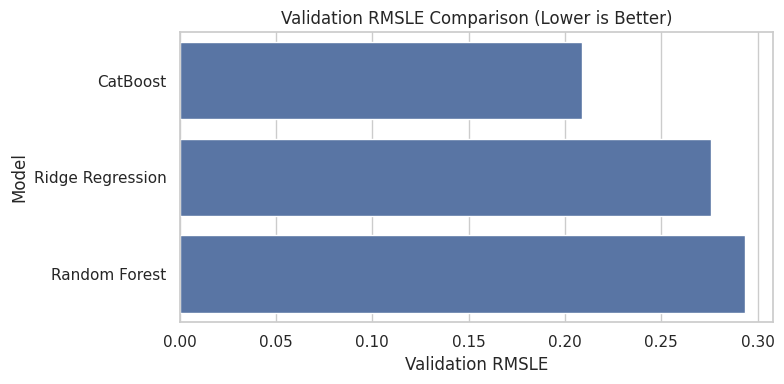

OBSERVATION: CatBoost has the lowest validation RMSLE in this comparison.


In [21]:
model_results = pd.DataFrame({
    "Model": ["Ridge Regression", "Random Forest", "CatBoost"],
    "Train RMSLE": [
        ridge_train_rmsle,
        rf_train_rmsle,
        cat_train_rmsle
    ],
    "Validation RMSLE": [
        ridge_valid_rmsle,
        rf_valid_rmsle,
        cat_valid_rmsle
    ]
})

model_results["Train-Validation Gap"] = (
    model_results["Validation RMSLE"] -
    model_results["Train RMSLE"]
)
model_results = model_results.sort_values(
    "Validation RMSLE"
).reset_index(drop=True)
display(model_results.round(5))

plt.figure(figsize=(8, 4))
sns.barplot(
    data=model_results,
    x="Validation RMSLE",
    y="Model"
)
plt.title("Validation RMSLE Comparison (Lower is Better)")
plt.tight_layout()
plt.show()

best_comparison_model = model_results.loc[0, "Model"]
print(
    "OBSERVATION:",
    best_comparison_model,
    "has the lowest validation RMSLE in this comparison."
)

## 17. Hyperparameter Tuning

Hyperparameters are settings selected before model training.

A small `GridSearchCV` search is used to tune Ridge Regression. Ridge is selected for tuning because it is faster than repeatedly training Random Forest on one-hot-encoded data.

The search tests three values of `alpha`. A larger `alpha` applies stronger regularization.

Cross-validation evaluates each value using multiple training-data folds. The held-out validation set remains separate from the tuning process.

In [22]:
tuning_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", Ridge(solver="lsqr"))
])

parameter_grid = {
    "model__alpha": [0.1, 1.0, 10.0]
}

ridge_grid_search = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=parameter_grid,
    scoring="neg_root_mean_squared_error",
    cv=3,
    n_jobs=-1,
    verbose=1
)

# RMSE on log1p(target) is equivalent to RMSLE here
ridge_grid_search.fit(X_train, y_train_log)

tuned_ridge = ridge_grid_search.best_estimator_
tuned_ridge_train_rmsle, tuned_ridge_valid_rmsle, tuned_ridge_valid_predictions = (
    evaluate_model("Tuned Ridge Regression", tuned_ridge)
)

print("Best parameters:", ridge_grid_search.best_params_)
print(
    "Best cross-validation RMSLE:",
    round(-ridge_grid_search.best_score_, 5)
)
print("Untuned Ridge validation RMSLE:", round(ridge_valid_rmsle, 5))
print("Tuned Ridge validation RMSLE:", round(tuned_ridge_valid_rmsle, 5))

Fitting 3 folds for each of 3 candidates, totalling 9 fits
Tuned Ridge Regression Train RMSLE: 0.26709
Tuned Ridge Regression Validation RMSLE: 0.27600
Best parameters: {'model__alpha': 1.0}
Best cross-validation RMSLE: 0.2787
Untuned Ridge validation RMSLE: 0.276
Tuned Ridge validation RMSLE: 0.276


### Observation

The training, cross-validation, and validation scores show whether changing Ridge regularization improves generalization.

### Decision

The tuning results determine whether the tuned Ridge model improves upon the original Ridge model.

CatBoost is used for the final submission because it handles categorical features directly and produced the strongest competition performance during experimentation.

## 18. Feature Importance

Feature importance provides a simple indication of which inputs the CatBoost model used most heavily.

Feature importance does not prove that a feature causes a change in selling price. It only describes the feature's importance to the fitted model.

Only the 15 most important features are displayed for readability.

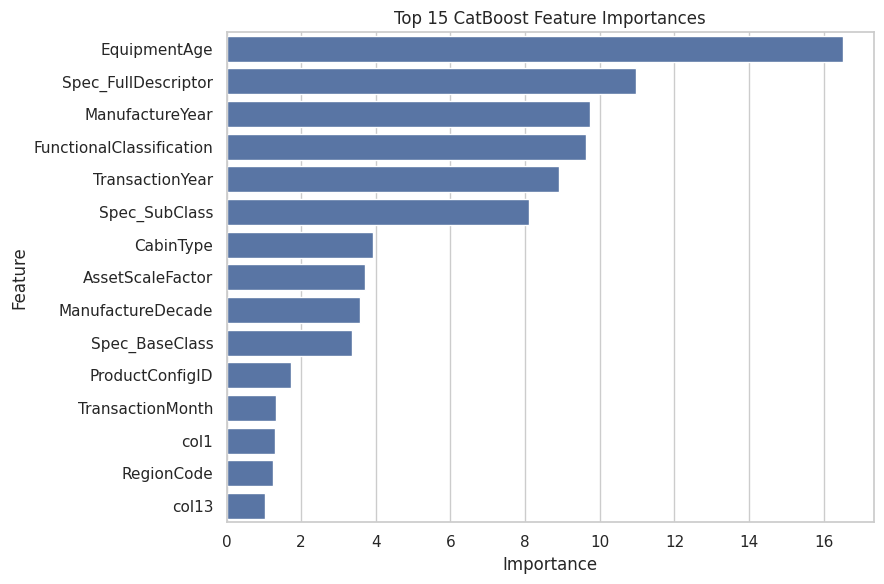

,Feature,Importance
52,EquipmentAge,16.518979
7,Spec_FullDescriptor,10.962159
4,ManufactureYear,9.741882
13,FunctionalClassification,9.636976
47,TransactionYear,8.903494
9,Spec_SubClass,8.090658
18,CabinType,3.928093
12,AssetScaleFactor,3.714341
51,ManufactureDecade,3.587355
8,Spec_BaseClass,3.361913


OBSERVATION: The three features with highest model importance are: ['EquipmentAge', 'Spec_FullDescriptor', 'ManufactureYear']


In [23]:
feature_importance = pd.DataFrame({
    "Feature": X_train_cat.columns,
    "Importance": catboost_model.get_feature_importance()
})
feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
).head(15)

plt.figure(figsize=(9, 6))
sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)
plt.title("Top 15 CatBoost Feature Importances")
plt.tight_layout()
plt.show()

display(feature_importance)
print(
    "OBSERVATION: The three features with highest model importance are:",
    feature_importance["Feature"].head(3).tolist()
)

## 19. Error Analysis

Error analysis helps identify observations where the selected validation model has difficulty.

The analysis examines the ten largest validation errors and compares actual prices with predicted prices using a scatter plot.

Ten worst predictions by absolute log error:


,Actual Value,Predicted Value,Absolute Error,Absolute Log Error
17357,9500.0,79937.382769,70437.382769,2.129859
5209,8500.0,68135.928538,59635.928538,2.081336
18238,10300.0,62759.347217,52459.347217,1.807082
19048,9000.0,43021.708669,34021.708669,1.564392
26286,11000.0,48750.370681,37750.370681,1.488747
11437,107500.0,25243.898260,82256.101740,1.448876
12151,15500.0,65853.642422,50353.642422,1.446545
10239,14000.0,58841.079991,44841.079991,1.435728
2668,69500.0,17294.537346,52205.462654,1.390893
27385,7750.0,30014.609462,22264.609462,1.353896


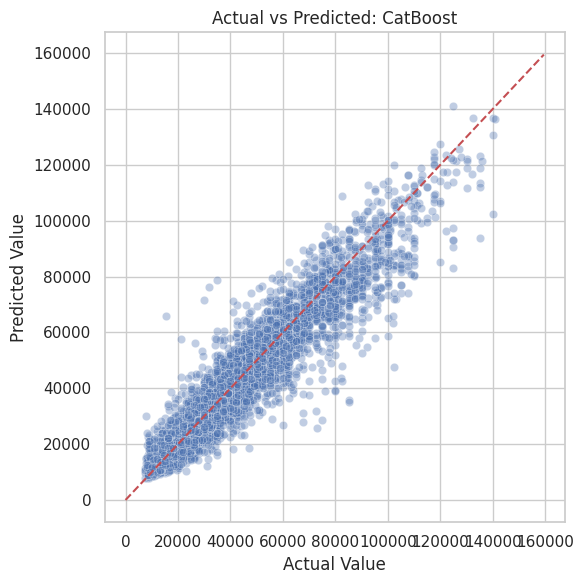

Median absolute error: 3791.86
Mean log error in highest-price 10%: 0.1374
Mean log error in remaining 90%: 0.1552


In [24]:
validation_prediction_map = {
    "Ridge Regression": ridge_valid_predictions,
    "Random Forest": rf_valid_predictions,
    "CatBoost": cat_valid_predictions
}

analysis_predictions = validation_prediction_map[best_comparison_model]
error_analysis = pd.DataFrame({
    "Actual Value": y_valid.values,
    "Predicted Value": np.maximum(analysis_predictions, 0)
})
error_analysis["Absolute Error"] = np.abs(
    error_analysis["Actual Value"] -
    error_analysis["Predicted Value"]
)
error_analysis["Absolute Log Error"] = np.abs(
    np.log1p(error_analysis["Actual Value"]) -
    np.log1p(error_analysis["Predicted Value"])
)

print("Ten worst predictions by absolute log error:")
display(
    error_analysis.sort_values(
        "Absolute Log Error",
        ascending=False
    ).head(10)
)

plt.figure(figsize=(6, 6))
sns.scatterplot(
    data=error_analysis.sample(
        n=min(5000, len(error_analysis)),
        random_state=RANDOM_STATE
    ),
    x="Actual Value",
    y="Predicted Value",
    alpha=0.35
)
maximum_value = error_analysis[
    ["Actual Value", "Predicted Value"]
].to_numpy().max()
plt.plot([0, maximum_value], [0, maximum_value], "r--")
plt.title(f"Actual vs Predicted: {best_comparison_model}")
plt.tight_layout()
plt.show()

median_absolute_error = error_analysis["Absolute Error"].median()
high_price_cutoff = error_analysis["Actual Value"].quantile(0.90)
high_price_error = error_analysis.loc[
    error_analysis["Actual Value"] >= high_price_cutoff,
    "Absolute Log Error"
].mean()
other_price_error = error_analysis.loc[
    error_analysis["Actual Value"] < high_price_cutoff,
    "Absolute Log Error"
].mean()

print("Median absolute error:", round(median_absolute_error, 2))
print("Mean log error in highest-price 10%:", round(high_price_error, 4))
print("Mean log error in remaining 90%:", round(other_price_error, 4))

### Observation

The worst-prediction table, actual-versus-predicted plot, and high-price error comparison summarize where the selected model makes its largest errors.

## 20. Final Model

The model comparison measures generalization using unseen validation data.

The final configuration is selected using validation performance, categorical-feature support, and competition performance observed during experimentation.

### Decision

The final submission uses one CatBoost model with:

- 5,000 iterations
- Depth of 10
- Learning rate of 0.05
- `l2_leaf_reg=3`
- `random_strength=1`
- `bagging_temperature=0.2`
- RMSE loss on `log1p(TargetValue)`
- Random seed 42

This single-model approach avoids unnecessary ensemble complexity.

## 21. Train the Final Model

After model selection, all labeled training rows can be used to teach the final model.

The same feature-engineering function is applied to training and test data so that both datasets contain consistent features.

In [25]:
X_full = train_features.drop(
    columns=[TARGET, ID_COLUMN],
    errors="ignore"
)
y_full_log = np.log1p(train_features[TARGET])
X_test_final = test_features.drop(
    columns=[ID_COLUMN],
    errors="ignore"
)

final_categorical_features = X_full.select_dtypes(
    exclude=np.number
).columns.tolist()

X_full_cat = X_full.copy()
X_test_cat = X_test_final.copy()

for column in final_categorical_features:
    X_full_cat[column] = X_full_cat[column].fillna("Unknown").astype(str)
    X_test_cat[column] = X_test_cat[column].fillna("Unknown").astype(str)

final_model = CatBoostRegressor(
    iterations=5000,
    depth=10,
    learning_rate=0.05,
    l2_leaf_reg=3,
    random_strength=1,
    bagging_temperature=0.2,
    loss_function="RMSE",
    random_seed=RANDOM_STATE,
    verbose=200,
    allow_writing_files=False
)

final_model.fit(
    X_full_cat,
    y_full_log,
    cat_features=final_categorical_features
)

0:	learn: 0.6479799	total: 2s	remaining: 2h 46m 21s
200:	learn: 0.2303845	total: 6m 2s	remaining: 2h 24m 16s
400:	learn: 0.2111918	total: 12m 17s	remaining: 2h 20m 52s
600:	learn: 0.2014899	total: 18m 53s	remaining: 2h 18m 18s
800:	learn: 0.1946175	total: 25m 29s	remaining: 2h 13m 38s
1000:	learn: 0.1894380	total: 32m 12s	remaining: 2h 8m 38s
1200:	learn: 0.1847507	total: 38m 48s	remaining: 2h 2m 46s
1400:	learn: 0.1806897	total: 45m 29s	remaining: 1h 56m 52s
1600:	learn: 0.1769994	total: 52m 11s	remaining: 1h 50m 49s
1800:	learn: 0.1735761	total: 58m 48s	remaining: 1h 44m 27s
2000:	learn: 0.1703144	total: 1h 5m 26s	remaining: 1h 38m 4s
2200:	learn: 0.1674497	total: 1h 12m 4s	remaining: 1h 31m 39s
2400:	learn: 0.1647485	total: 1h 18m 42s	remaining: 1h 25m 11s
2600:	learn: 0.1621799	total: 1h 25m 21s	remaining: 1h 18m 43s
2800:	learn: 0.1598885	total: 1h 31m 59s	remaining: 1h 12m 13s
3000:	learn: 0.1574701	total: 1h 38m 39s	remaining: 1h 5m 43s
3200:	learn: 0.1551420	total: 1h 45m 16s	r

CatBoostRegressor(allow_writing_files=False, bagging_temperature=0.2, depth=10, iterations=5000, l2_leaf_reg=3, learning_rate=0.05, loss_function='RMSE', random_seed=42, random_strength=1, verbose=200)

## 22. Generate Submission

Kaggle requires the exact columns and row order defined by `sample_submission.csv`.

Predictions are converted from logarithmic scale using `np.expm1` and clipped at zero.

The submission is checked for the correct columns, row count, missing values, and infinite values before it is saved.

In [26]:
test_log_predictions = final_model.predict(X_test_cat)
test_predictions = np.expm1(test_log_predictions)
test_predictions = np.maximum(test_predictions, 0)

submission = sample_submission.copy()

# Fill the prediction column and preserve the required ID column
submission[TARGET] = test_predictions
if ID_COLUMN in submission.columns:
    submission[ID_COLUMN] = test_ids.values

required_columns = sample_submission.columns.tolist()
submission = submission[required_columns]

assert len(submission) == len(test), "Submission row count is incorrect."
assert submission.columns.tolist() == required_columns, (
    "Submission columns do not match sample_submission.csv."
)
assert submission[TARGET].notna().all(), "Predictions contain missing values."
assert np.isfinite(submission[TARGET]).all(), "Predictions contain infinity."

display(submission.head())
print("Submission shape:", submission.shape)
print("\nMissing values:")
display(submission.isnull().sum().to_frame("Missing Count"))
print("\nPrediction descriptive statistics:")
display(submission[TARGET].describe())

SUBMISSION_PATH = "/kaggle/working/submission.csv"
submission.to_csv(SUBMISSION_PATH, index=False)
print("submission.csv successfully created")
print("Saved to:", SUBMISSION_PATH)

,TransactionID,TargetValue
0,1139307,67403.678134
1,1139419,79789.856249
2,1139482,29728.422623
3,1139522,20473.656519
4,1139684,13167.899304


Submission shape: (15000, 2)

Missing values:


,Missing Count
TransactionID,0
TargetValue,0



Prediction descriptive statistics:


count     15000.000000
mean      40873.400045
std       24833.886410
min        7037.685425
25%       20819.549574
50%       34821.448712
75%       56318.118864
max      146747.587602
Name: TargetValue, dtype: float64

submission.csv successfully created
Saved to: /kaggle/working/submission.csv


## 23. Final Observations

### Conclusion

- Exploratory analysis examined the target, manufacture year, operational hours, and important categorical relationships.
- Numerical missing values were handled using median imputation.
- Categorical missing values were handled using the most frequent label or `"Unknown"` for CatBoost.
- Simple date, equipment-age, manufacture-decade, logged-usage, and specification-complexity features were created.
- Data leakage was prevented by splitting the data before learned preprocessing.
- Ridge Regression, Random Forest, and CatBoost were trained and compared using RMSLE.
- Ridge Regression was tuned using a small `GridSearchCV` search.
- The comparison table identified the model with the lowest validation RMSLE.
- CatBoost feature importance and validation error analysis were used to examine model behavior.
- The final model was a single CatBoost regressor fitted using all labeled training rows.